In [1]:
import torch
import torch.nn as nn
import torch.nn.init as init
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import dcor
import time
import numpy as np
import pandas as pd
from mynet import *
from support_function import *
from DenseNet import *
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from sklearn.model_selection import GridSearchCV

### My Net Below

In [ ]:
import torch
import torch.nn as nn
import torch.nn.init as init
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset
import dcor
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from torchvision.models import resnet18
from torchvision import models
from support_function import *

def init_weights(m):
    if isinstance(m, nn.Linear):
        init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        if m.bias is not None:
            init.constant_(m.bias, 0)


class ResNet18(nn.Module):
    def __init__(self, num_classes=2):
        super(ResNet18, self).__init__()
        self.model = resnet18(weights=None)
        self.model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)  
        self.model.fc = nn.Linear(self.model.fc.in_features, num_classes)  
    
    def forward(self, x):
        return self.model(x)

class CustomResNet50(nn.Module):
    def __init__(self, output_dim):
        super(CustomResNet50, self).__init__()

        self.resnet50 = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

        self.resnet50.conv1 = nn.Conv2d(
            1, 64, kernel_size=7, stride=2, padding=3, bias=False)

        num_ftrs = self.resnet50.fc.in_features
        self.resnet50.fc = nn.Linear(num_ftrs, output_dim)

    def forward(self, x):
        return self.resnet50(x)    

class CustomDenseNet121(nn.Module):
    def __init__(self, output_dim):
        super(CustomDenseNet121, self).__init__()

        self.densenet = models.densenet121(weights=None)

        self.densenet.features.conv0 = nn.Conv2d(
            1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        
        num_ftrs = self.densenet.classifier.in_features
        self.densenet.classifier = nn.Linear(num_ftrs, output_dim)

    def forward(self, x):
        return self.densenet(x)    

class EarlyStopping:
    def __init__(self, patience=10, verbose=False, delta=0):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.Inf
        self.delta = delta

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        """Saves model when validation loss decreases."""
        if self.verbose:
            print(f"Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model ...")
        torch.save(model.state_dict(), "checkpoint.pt")
        self.val_loss_min = val_loss


class CustomNet(nn.Module):
     
    def __init__(self, architecture='FNN', optimizer_name='Adam', blambda=0.01, device='cpu', output_dim=10,
                p_dim=10, batch_size=100, iter_num=100, dist_mode=0, lr=1e-3):
        
        super(CustomNet, self).__init__()
        self.device = torch.device(device)
        self.output_dim = output_dim
        self.blambda = blambda
        self.p_dim = p_dim
        self.batch_size = batch_size
        self.iter_num = iter_num
        self.dist_mode = dist_mode
        self.lr = lr
        self.arch = architecture

        if architecture == 'FNN':
            self.model = self.build_fnn()
        elif architecture == 'LeNet':
            self.model = self.lenet_mnist()
        elif architecture == 'ResNet':
            self.model = ResNet18(self.output_dim)
        elif architecture == 'DenseNet':
            self.model = DenseNet(growthRate=12, depth=100, reduction=0.5, bottleneck=True, ndim = self.output_dim)
        else:
            raise ValueError("Unsupported architecture type")

        self.model.apply(init_weights)
        self.model.to(self.device)

        if optimizer_name == 'Adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr)
        elif optimizer_name == 'SGD':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.lr, momentum=0.9)
        else:
            raise ValueError("Unsupported optimizer type")
    
    def build_fnn(self):
        max_width = 7 # 6
        init_width = 6 # 5
        min_width = 3 # 2
        middle = 0
        layers = [
            nn.Linear(self.p_dim, 2**init_width),  
            nn.ReLU()
        ]

        for i in range(init_width, max_width):
            layers.append(nn.Linear(2**i, 2** (i+1)))
            layers.append(nn.ReLU())

        for _ in range(middle):
            layers.append(nn.Linear(2**max_width, 2**max_width))
            layers.append(nn.ReLU())
        
        for i in range(max_width, min_width, -1):
            layers.append(nn.Linear(2**i, 2**(i-1)))
            layers.append(nn.ReLU())


        layers.append(nn.Linear(2**min_width, self.output_dim))

        return nn.Sequential(*layers)    

    def build_lenet(self): 
        layers = [nn.Conv2d(1, 6, kernel_size=5, padding=2),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  
            nn.Conv2d(6, 16, kernel_size=5),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), 
            nn.Conv2d(16, 32, kernel_size=5, padding=2),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  
            nn.Conv2d(32, 64, kernel_size=5, padding=2),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Flatten(), 
            nn.Linear(1600, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, self.output_dim)]
        return nn.Sequential(*layers)

    def lenet_mnist(self): 
        layers = [nn.Conv2d(1, 6, kernel_size=5, padding=2),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  
            nn.Conv2d(6, 16, kernel_size=5),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), 
            nn.Conv2d(16, 32, kernel_size=3, padding=1),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  
            nn.Flatten(), 
            nn.Linear(128, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, self.output_dim)]
        return nn.Sequential(*layers)
    
    def forward(self, x):
        return self.model(x)
    
    def train_step(self, data, target, loss_fn):
        if not isinstance(data, torch.Tensor):
            data = torch.tensor(data, dtype=torch.float32)
        if not isinstance(target, torch.Tensor):
            target = torch.tensor(target, dtype=torch.float32)

        self.model.train()
        print("Net starts training")
        
        for epoch in range(self.iter_num):
            dataset = TensorDataset(data, target)
            dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

            total_loss = 0
            for data_batch, target_batch in dataloader:

                data_batch, target_batch = data_batch.to(self.device), target_batch.to(self.device)
                self.optimizer.zero_grad()
                outputs = self.model(data_batch)
                loss = loss_fn(outputs, target_batch)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()
            
            if self.arch=='DCNN':
                self.scheduler.step()
            avg_loss = total_loss / len(dataloader)
            if epoch%(self.iter_num/10)==0:
                print(f"epoch:{epoch}, avg_loss:",avg_loss)
        
    
    def train_step_early(self, data, target, val_data, val_target, loss_fn, patience=10):

        early_stopping = EarlyStopping(patience=patience, verbose=False)

        if not isinstance(data, torch.Tensor):
            data = torch.tensor(data, dtype=torch.float32)
            val_data = torch.tensor(val_data, dtype=torch.float32)
        if not isinstance(target, torch.Tensor):
            target = torch.tensor(target, dtype=torch.float32)
            val_target = torch.tensor(val_target, dtype=torch.float32)
        

        val_data, val_target = val_data.to(self.device), val_target.to(self.device)

        self.model.train()
        print("Net starts training")
        
        for epoch in range(self.iter_num):
            dataset = TensorDataset(data, target)
            dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)
            
            for data_batch, target_batch in dataloader:

                data_batch, target_batch = data_batch.to(self.device), target_batch.to(self.device)

                total_loss = 0

                self.optimizer.zero_grad()
                outputs = self.model(data_batch)
                loss = loss_fn(outputs, target_batch)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item() * self.batch_size
                
            self.scheduler.step()
            avg_loss = total_loss / len(dataloader)


            self.model.eval()
            with torch.no_grad():
                val_outputs = self.model(val_data)
                val_loss = loss_fn(val_outputs, val_target).item()
                

            early_stopping(val_loss, self.model)

            if early_stopping.early_stop:
                print("Early stopping")
                break
                
        # 加载最佳模型状态
        self.model.load_state_dict(torch.load("checkpoint.pt"))
        
            
    def transform(self, test_data):
        self.model.eval()  
        outputs = []

        with torch.no_grad():
            if not isinstance(test_data, torch.Tensor):
                test_data = torch.tensor(test_data, dtype=torch.float32)


            total_data = test_data.size(0)
            for i in range(0, total_data, self.batch_size):

                batch_data = test_data[i:i+self.batch_size].to(self.device)
                batch_output = self.forward(batch_data)
                outputs.append(batch_output)


            output = torch.cat(outputs, dim=0)

            if not isinstance(output, np.ndarray):

                if isinstance(output, torch.Tensor):

                    output = output.cpu().numpy()
                else:
                    output = np.array(output)

        return output.astype(np.float32)

        
    def dist(self,y1,y2,mode):     
        if mode==0:
            distances = torch.norm(y1-y2, dim=2)
        elif mode==1:
            distances = torch.arccos(torch.einsum('ijk,ijk->ij', y1, y2))
        elif mode==2:
            distances = []
            for i in range(y1.shape[0]):
                dis = spd_dis(y1[i],y2[i])
                distances.append(dis)
            distances = torch.stack(distances)
        elif mode==3:
            z1 = torch.sqrt(y1)
            z2 = torch.sqrt(y2)
            distances = torch.norm(z1-z2, dim=2)/np.sqrt(2)
        elif mode==4:
            distances = 0.5*torch.sum(torch.abs(y1-y2), dim=2)
        elif mode==5:
            equal_elements = torch.eq(y1, y2)
            distances = torch.all(equal_elements, dim=2).float()
        return distances    
    
    def calculate_distances_and_sort_torch(self, X, Y, mode=0):
        d = X.dim()
        n = X.shape[0]
        mean_Y = torch.mean(Y, dim=0) if Y.shape[1] > 1 else torch.mean(Y)
        Y_combined = torch.empty_like(Y)
        if d==2:
            expanded_X = X.unsqueeze(1).expand(-1, n, -1)
            distances = self.dist(expanded_X, expanded_X.transpose(0, 1), mode)
        elif d==3:    
            expanded_X = X.unsqueeze(1).expand(-1, n, -1, -1)
            distances = self.dist(expanded_X, expanded_X.transpose(0, 1), mode)
    
        sorted_indices = torch.argsort(distances, dim=1)
        sorted_Y = torch.gather(Y.expand(n, -1, -1), 1, sorted_indices.unsqueeze(-1).expand(-1, -1, Y.shape[1]))

        Y_combined = sorted_Y - mean_Y
    
        return Y_combined
    
    
    def fast_cmp_torch(self, Y_sorted, Y):
        n = Y.shape[0]
        Y = Y - torch.mean(Y)
        Tnp = 0

        cumulative_sums = torch.cumsum(Y_sorted, dim=1)
        squared_cumsums = torch.sum(torch.square(cumulative_sums[:,:]), dim=1)
        Tnp += torch.sum(squared_cumsums)

        squared_Y_sorted = torch.square(Y_sorted)
        cumulative_sums_squares = torch.cumsum(squared_Y_sorted, dim=1)
        Tnp -= torch.sum(cumulative_sums_squares[:, :-1])

        Tnp -= 2 * torch.sum(Y @ cumulative_sums[:, :-1])

        Tnp += 2*(n-1)*torch.sum(Y**2)

        return Tnp / (n * (n-1) * (n-2) * (n-3))

    
    def mccov_value(self, yhat, y):

        mode = self.dist_mode
        yhat_sorted = self.calculate_distances_and_sort_torch(y, yhat, mode)  
        num = 0.0  

        if yhat.ndim == 1:
            num = self.fast_cmp_torch(yhat_sorted, yhat)
        elif yhat.ndim == 2:
            q = yhat.shape[1]
            for i in range(q):
                num += self.fast_cmp_torch(yhat_sorted[:, :, i], yhat[:, i])
        return -1.0*num

    def mccov_loss(self, yhat, y):          
        yhatdim = yhat.shape[1]
        cov_loss =  torch.norm((torch.cov(yhat.T).reshape(yhatdim, yhatdim) - torch.eye(yhatdim).to(self.device)), p='fro')**2
        mccov = self.mccov_value(yhat, y)
        return mccov + self.blambda * cov_loss


    def evaluate(self, test_loader):
        self.model.eval()  
        total_correct = 0
        total_samples = 0
        
        with torch.no_grad():
            for data, target in test_loader:
                data, target = data.to(self.device), target.to(self.device)
                outputs = self.model(data)
                _, predicted = torch.max(outputs.data, 1)
                total_samples += target.size(0)
                total_correct += (predicted == target).sum().item()
    
        accuracy = total_correct / total_samples
        print(f'Accuracy of the network on the test images: {accuracy * 100:.2f}%')
        return accuracy

### Data Load

In [ ]:

transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:

def convert_to_numpy(data_loader):
    data_list = []
    labels_list = []
    for images, labels in data_loader:
        data_list.append(images.numpy())
        labels_list.append(labels.numpy())
    data_array = np.concatenate(data_list, axis=0)
    labels_array = np.concatenate(labels_list, axis=0)
    return data_array, labels_array


train_data, train_label = convert_to_numpy(train_loader)


test_data, test_label = convert_to_numpy(test_loader)

In [5]:
device = 'cuda:0'

In [ ]:

def train(model, device, train_loader, optimizer, epoch, model_type='LeNet'):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        if (batch_idx + 1) % 100 == 0:
            print(f'Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} ({100. * batch_idx / len(train_loader):.0f}%)]\tLoss: {loss.item():.6f}')


def test(model, device, test_loader, model_type='LeNet'):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)
    print(f'\nTest set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(test_loader.dataset)} ({100. * correct / len(test_loader.dataset):.0f}%)\n')

### ResNet

In [ ]:

re_model = models.resnet18(pretrained=False, num_classes = 10)
re_model.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
re_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(re_model.parameters(), lr=0.001)

In [ ]:
for epoch in range(1, 11):  # 运行10个epoch
    train(re_model, device, train_loader, optimizer, epoch)
    test(re_model, device, test_loader)

### Get corresponding distribution

In [ ]:
def get_probabilities(data_loader, model, device):
    model.eval()
    probabilities = torch.Tensor().to(device)  
    with torch.no_grad():
        for data, _ in data_loader:
            data = data.to(device)
            output = model(data)
            prob = torch.softmax(output, dim=1)  
            probabilities = torch.cat((probabilities, prob), dim=0)  
    return probabilities.cpu().numpy()

In [ ]:
re_train_dis = get_probabilities(train_loader, re_model, device)
re_test_dis = get_probabilities(test_loader, re_model, device)

### MCCOV模型训练

In [ ]:

mnist_trainset = torchvision.datasets.MNIST(root='./data', train=True, download=False, transform=None)
mnist_testset = torchvision.datasets.MNIST(root='./data', train=False, download=False, transform=None)

x_train = mnist_trainset.data
x_train = x_train.to(torch.float32).reshape(-1, 1, 28, 28)
y_train = mnist_trainset.targets

x_test = mnist_testset.data
x_test = x_test.to(torch.float32).reshape(-1, 1, 28, 28)
y_test = mnist_testset.targets

#### LeNet

In [80]:
dist_mode = 3 # Hellinger
device = 'cuda:0'
arch = 'LeNet'
iter_num = 100
batch_size = 64
d = 3
bl = 1e-5

mccov_le = CustomNet(architecture=arch, optimizer_name='Adam', iter_num=iter_num, batch_size=batch_size, 
                  blambda=bl, dist_mode=dist_mode, device=device, output_dim=d)

In [81]:
mccov_le.train_step(train_data, re_train_dis, mccov_le.mccov_loss)

Net starts training
epoch:0, avg_loss: -13.390763542719641
epoch:10, avg_loss: -26.80641327534657
epoch:20, avg_loss: -28.103159849577622
epoch:30, avg_loss: -28.7373769268044
epoch:40, avg_loss: -29.160191948734113
epoch:50, avg_loss: -29.38751532223179
epoch:60, avg_loss: -29.605897035171736
epoch:70, avg_loss: -29.581682453277523
epoch:80, avg_loss: -29.730316735534018
epoch:90, avg_loss: -29.788164148961048


In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_le.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_le.transform(test_data)))

0.9289

In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_le.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_le.transform(test_data)))

0.9344

In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_le.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_le.transform(test_data)))

0.949

In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_le.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_le.transform(test_data)))

0.9497

#### DenseNet

In [83]:
dist_mode = 3 # Hellinger
device = 'cuda:0'
arch = 'DenseNet'
iter_num = 25
batch_size = 64
d = 3
bl = 1e-5

mccov_de = CustomNet(architecture=arch, optimizer_name='Adam', iter_num=iter_num, batch_size=batch_size, 
                  blambda=bl, dist_mode=dist_mode, device=device, output_dim=d)

In [84]:
mccov_de.train_step(train_data, re_train_dis, mccov_de.mccov_loss)

Net starts training
epoch:0, avg_loss: -18.089343955544734
epoch:5, avg_loss: -29.941219592145256
epoch:10, avg_loss: -32.6758652282422
epoch:15, avg_loss: -33.68807595625107
epoch:20, avg_loss: -34.27023261340696


In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_de.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_de.transform(test_data)))

0.9301

In [49]:
# 
lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_de.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_de.transform(test_data)))

0.9471

#### ResNet

In [101]:
dist_mode = 3 # Hellinger
device = 'cuda:0'
arch = 'ResNet'
iter_num = 50
batch_size = 64
d = 3
bl = 1e-5

mccov_re = CustomNet(architecture=arch, optimizer_name='Adam', iter_num=iter_num, batch_size=batch_size, 
                  blambda=bl, dist_mode=dist_mode, device=device, output_dim=d)

In [102]:
mccov_re.train_step(train_data, re_train_dis, mccov_re.mccov_loss)

Net starts training
epoch:0, avg_loss: -18.920349557770848
epoch:5, avg_loss: -31.439253965674688
epoch:10, avg_loss: -33.34120993624364
epoch:15, avg_loss: -34.232449318046
epoch:20, avg_loss: -35.076279235547034
epoch:25, avg_loss: -35.31901703816233
epoch:30, avg_loss: -35.66013267655362
epoch:35, avg_loss: -36.03587103805054
epoch:40, avg_loss: -36.104760090679505
epoch:45, avg_loss: -36.152152931766466


In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_re.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_re.transform(test_data)))

0.9232

In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(mccov_re.transform(train_data), train_label)
accuracy_score(test_label, lrflenet.predict(mccov_re.transform(test_data)))

0.9189

### GMDD-Net training

In [ ]:
import torch, time, dcor
import numpy as np
from torch import nn
from NSDR import NSDR
from rpy2.robjects.packages import importr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from torchvision.models import resnet18
import torchvision
import warnings
importr("nsdr")

In [ ]:
from IPython.core.magic import register_cell_magic
import traceback

@register_cell_magic('captureerror_without_halting')
def captureerror_without_halting(file, cell):
    file = eval(file)
    try:
        exec(cell, globals())
    except Exception as e:
        file.write(traceback.format_exc() + "\n")
        file.flush()

In [63]:
# the result u generate may differ from the pdf cuz i don't set global random seed.
global_debug_flag= False
global_training_flag = True ## whether training from scratch

In [39]:
def init_xv_uniform(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)
        nn.init.zeros_(m.bias)

In [40]:
x_train = train_data 
y_train = train_label
x_test = test_data
y_test = test_label

d=3

#### GMDD数据标准化

In [ ]:

mnist_trainset = torchvision.datasets.MNIST(root='./data', train=True, download=False, transform=None)
mnist_testset = torchvision.datasets.MNIST(root='./data', train=False, download=False, transform=None)

x_train = mnist_trainset.data
x_train = x_train.to(torch.float32).reshape(-1, 1, 28, 28)
y_train = mnist_trainset.targets

x_test = mnist_testset.data
x_test = x_test.to(torch.float32).reshape(-1, 1, 28, 28)
y_test = mnist_testset.targets

n = x_train.shape[0]
p = x_train.shape[1]
d = 3

#### LeNet

In [41]:
lenetseq = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(400, 120), nn.Sigmoid(),
            nn.Linear(120, 84), nn.Sigmoid(),
            nn.Linear(84, 1)
     )  # net 1

lenetdr = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5), nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(400, 120), nn.Sigmoid(),
            nn.Linear(120, 84), nn.Sigmoid(),
            nn.Linear(84, d)
     )  # net 1
lenetdr.apply(init_xv_uniform)

Sequential(
  (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (1): Sigmoid()
  (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (4): Sigmoid()
  (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=400, out_features=120, bias=True)
  (8): Sigmoid()
  (9): Linear(in_features=120, out_features=84, bias=True)
  (10): Sigmoid()
  (11): Linear(in_features=84, out_features=3, bias=True)
)

In [42]:
# the result u generate may differ from the pdf cuz i don't set global random seed.
global_debug_flag= False
global_training_flag = False ## whether training from scratch

In [109]:
model = NSDR(neural_network=lenetseq, categorical_y=True,
             max_dim=1, method = "seq", adaptive_cv=False, retrain = True, 
             debug=global_debug_flag, device="cuda:0", optimizer="adam", 
             iter_num=200, early_stop=False)
model.fit(x_train, y_train)
bllen = -model.get_sample_gmdd_value(x_train, y_train, batch_average=True)
print(bllen)

0.10970828


In [110]:
modelFLE = NSDR(neural_network=lenetdr, initial_blambda = np.sqrt(d) * bllen, 
                categorical_y=True, max_dim=1, method = "fnorm", adaptive_cv=False,
                retrain = True, debug=global_debug_flag, device="cuda:0", 
                optimizer="adam", iter_num=200, early_stop=False)
modelFLE.fit(x_train, y_train)

NSDR(categorical_y=True, device='cuda:0', initial_blambda=0.19002031388198565,
     iter_num=200, method='fnorm', neural_network=124487757996384, y_mode=6)

In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(modelFLE.transform(x_train), y_train)
accuracy_score(y_test, lrflenet.predict(modelFLE.transform(x_test)))

0.6303

#### DenseNet

In [59]:
densenetdr = DenseNet(growthRate=12, depth=100, reduction=0.5, bottleneck=True, ndim = d)
densenetseq = DenseNet(growthRate=12, depth=100, reduction=0.5, bottleneck=True, ndim = 1)

In [ ]:
# %%captureerror_without_halting file_to_training_state
start_time = time.time()
if global_training_flag:
    model = NSDR(neural_network=densenetseq, categorical_y=True,
                 max_dim=1, method = "seq", adaptive_cv=False, retrain = True, 
                 debug=global_debug_flag, device="cuda:1", optimizer="adam", 
                 iter_num=100, early_stop=False)
    model.fit(x_train, y_train)
    bldense = -model.get_sample_gmdd_value(x_train, y_train, batch_average=True)
    print(bldense)
    modelFDEN = NSDR(neural_network=densenetdr, initial_blambda = np.sqrt(d) * bldense, 
                    categorical_y=True, max_dim=1, method = "fnorm", adaptive_cv=False,
                    retrain = True, debug=global_debug_flag, device="cuda:1", 
                    optimizer="adam", iter_num=100, early_stop=False)
    modelFDEN.fit(x_train, y_train)
total_time = time.time() - start_time

0.106345855


In [ ]:

lrflenet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrflenet.fit(modelFDEN.transform(x_train), y_train)
accuracy_score(y_test, lrflenet.predict(modelFDEN.transform(x_test)))

0.9083

#### ResNet

In [ ]:
resnetdr = resnet18(num_classes = d)
resnetdr.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
resnetseq = resnet18(num_classes = 1)
resnetseq.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)

In [71]:
if global_training_flag:
    model = NSDR(neural_network=resnetseq, categorical_y=True,
                 max_dim=1, method = "seq", adaptive_cv=False, retrain = True, 
                 debug=global_debug_flag, device="cuda:1", optimizer="adam", 
                 iter_num=100, early_stop=False)
    model.fit(x_train, y_train)
    blres = -model.get_sample_gmdd_value(x_train, y_train, batch_average=True)
    print(blres)
    modelFRES = NSDR(neural_network=resnetdr, initial_blambda = np.sqrt(d) * blres, 
                    categorical_y=True, max_dim=1, method = "fnorm", adaptive_cv=False,
                    retrain = True, debug=global_debug_flag, device="cuda:1", 
                    optimizer="adam", iter_num=100, early_stop=False)
    modelFRES.fit(x_train, y_train)

0.106954105


In [72]:
lrfresnet = LogisticRegression(multi_class="multinomial", max_iter=1000, solver='saga')
lrfresnet.fit(modelFRES.transform(x_train), y_train)
accuracy_score(y_test, lrfresnet.predict(modelFRES.transform(x_test)))

0.9056

### 3d visulization

In [97]:
d3_data_g = modelFDEN.transform(x_train)
d3_data_m = mccov_le.transform(train_data)

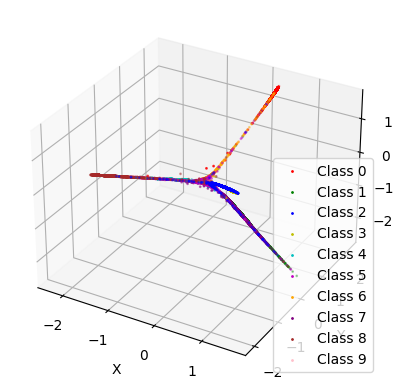

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')


colors = ['r', 'g', 'b', 'y', 'c', 'm', 'orange', 'purple', 'brown', 'pink']


for label in range(10):
    indices = np.where(train_label == label)
    ax.scatter(d3_data_g[indices, 0], d3_data_g[indices, 1], d3_data_g[indices, 2], c=colors[label], label=f'Class {label}', s=1)


ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')


ax.legend()
plt.savefig('data/3d_gmdd')


plt.show()

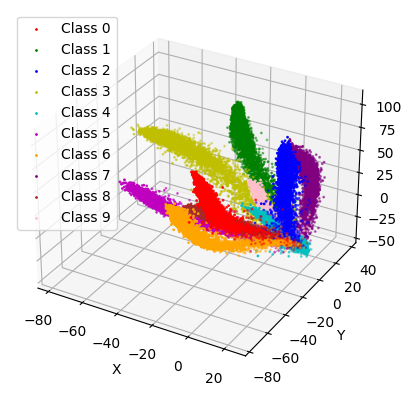

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')


colors = ['r', 'g', 'b', 'y', 'c', 'm', 'orange', 'purple', 'brown', 'pink']


for label in range(10):
    indices = np.where(train_label == label)
    ax.scatter(d3_data_m[indices, 0], d3_data_m[indices, 1], d3_data_m[indices, 2], c=colors[label], label=f'Class {label}', s=1)


ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')


ax.legend()
plt.savefig('data/3d_mccov')


plt.show()